# Exploratory Data Analysis

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('../data/processed/events_clean.csv')

In [3]:
df['datetime'] = pd.to_datetime(df['datetime'])

In [4]:
df.shape

(2755641, 5)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2755641 entries, 0 to 2755640
Data columns (total 5 columns):
 #   Column         Dtype         
---  ------         -----         
 0   visitorid      int64         
 1   event          str           
 2   itemid         int64         
 3   transactionid  float64       
 4   datetime       datetime64[us]
dtypes: datetime64[us](1), float64(1), int64(2), str(1)
memory usage: 105.1 MB


In [6]:
df.head()

,visitorid,event,itemid,transactionid,datetime
0,257597,view,355908,NaN,2015-06-02 05:02:12.117
1,992329,view,248676,NaN,2015-06-02 05:50:14.164
2,111016,view,318965,NaN,2015-06-02 05:13:19.827
3,483717,view,253185,NaN,2015-06-02 05:12:35.914
4,951259,view,367447,NaN,2015-06-02 05:02:17.106


### Число событий каждого типа

In [7]:
df['event'].value_counts()

event
view           2664218
addtocart        68966
transaction      22457
Name: count, dtype: int64

### Доля событий каждого типа

In [8]:
event_share_pct = df["event"].value_counts(normalize=True).mul(100).round(2)
event_share_pct

event
view           96.68
addtocart       2.50
transaction     0.81
Name: proportion, dtype: float64

### Количество событий по дням

In [9]:
daily_events = df.groupby(df["datetime"].dt.floor("D")).size()
daily_events

datetime
2015-05-03    13682
2015-05-04    19413
2015-05-05    23011
2015-05-06    23920
2015-05-07    23157
              ...  
2015-09-14    20905
2015-09-15    20425
2015-09-16    11494
2015-09-17    10126
2015-09-18     1528
Length: 139, dtype: int64

In [10]:
daily_events.sum()

np.int64(2755641)

In [11]:
daily_events.iloc[1:-1].describe()

count      137.000000
mean     20003.145985
std       3856.666965
min      10126.000000
25%      16971.000000
50%      20748.000000
75%      22548.000000
max      32692.000000
dtype: float64

В среднем за день было около 20 тысяч событий, медиана - 20 748
Значения менялись от 10 126 до 32 692

In [14]:
unique_vis_daily_events = df.groupby(df['datetime'].dt.floor("D"))['visitorid'].nunique()
unique_vis_daily_events

datetime
2015-05-03     7865
2015-05-04    11019
2015-05-05    13084
2015-05-06    13687
2015-05-07    13086
              ...  
2015-09-14    13389
2015-09-15    12687
2015-09-16     6824
2015-09-17     6270
2015-09-18     1016
Name: visitorid, Length: 139, dtype: int64

In [15]:
df['visitorid'].nunique()

1407580

### Событий на одного активного пользователя в каждом дне

In [19]:
event_on_visitor = daily_events/unique_vis_daily_events
event_on_visitor

datetime
2015-05-03    1.739606
2015-05-04    1.761775
2015-05-05    1.758713
2015-05-06    1.747644
2015-05-07    1.769601
                ...   
2015-09-14    1.561356
2015-09-15    1.609916
2015-09-16    1.684349
2015-09-17    1.614992
2015-09-18    1.503937
Length: 139, dtype: float64

In [21]:
event_on_visitor.iloc[1:-1].describe()

count    137.000000
mean       1.666757
std        0.078221
min        1.424431
25%        1.609916
50%        1.665315
75%        1.720992
max        1.866408
dtype: float64

За 137 полных дней среднее дневное отношение составило 1,67 события на активного пользователя
По дням оно менялось от 1,42 до 1,87

In [25]:
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


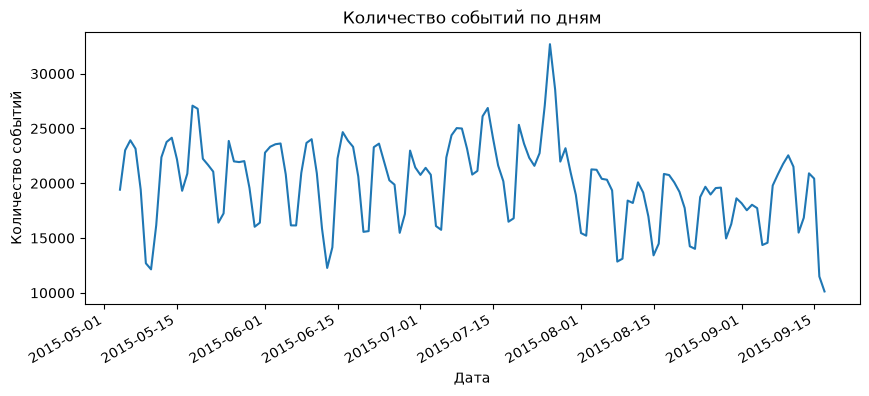

In [26]:
full_days = daily_events.iloc[1:-1]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(full_days.index, full_days.values)
ax.set_title("Количество событий по дням")
ax.set_xlabel("Дата")
ax.set_ylabel("Количество событий")
fig.autofmt_xdate()
plt.show()

In [27]:
weekday_avg = full_days.groupby(full_days.index.day_of_week).mean().round(0)
weekday_avg.index = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
weekday_avg

Пн    21987.0
Вт    22350.0
Ср    21553.0
Чт    20934.0
Пт    19900.0
Сб    16061.0
Вс    16879.0
dtype: float64

В период наблюдения активность по выходным была ниже, чем по будням
Это соответствует повторяющимся спадам на дневном графике

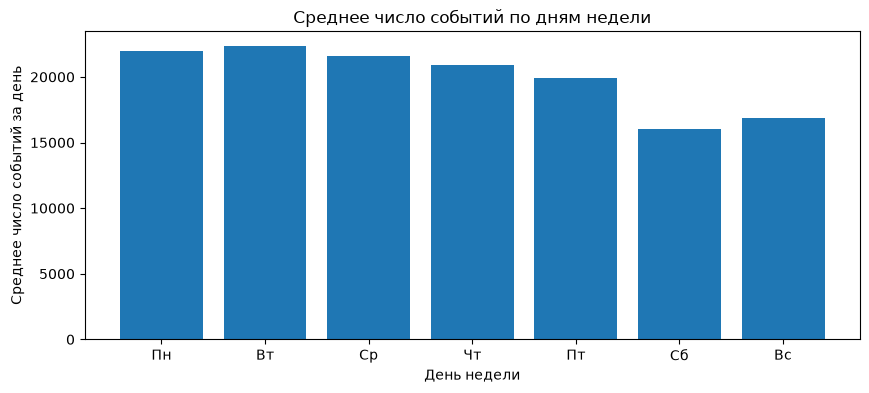

In [30]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(weekday_avg.index, weekday_avg.values)
ax.set_title("Среднее число событий по дням недели")
ax.set_xlabel("День недели")
ax.set_ylabel("Среднее число событий за день")
plt.show()

In [32]:
full_uhique_ve = unique_vis_daily_events.iloc[1:-1]
full_uhique_ve

datetime
2015-05-04    11019
2015-05-05    13084
2015-05-06    13687
2015-05-07    13086
2015-05-08    11106
              ...  
2015-09-13    10768
2015-09-14    13389
2015-09-15    12687
2015-09-16     6824
2015-09-17     6270
Name: visitorid, Length: 137, dtype: int64

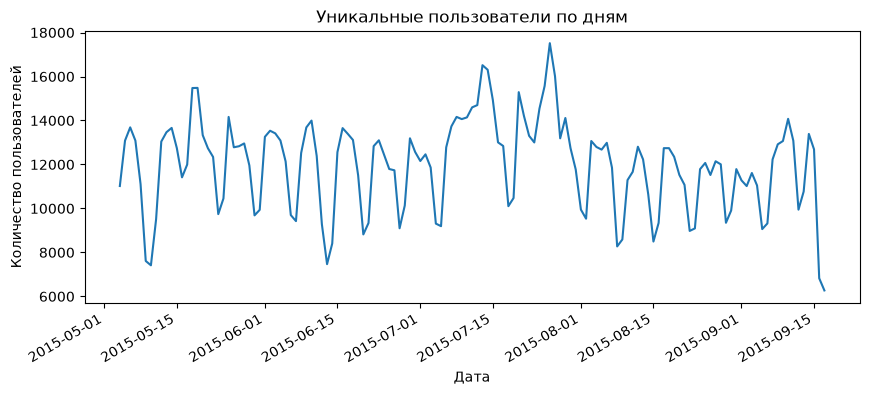

In [43]:
fig, ax = plt.subplots(figsize = (10,4))

ax.plot(full_uhique_ve.index, full_uhique_ve.values)
ax.set_title('Уникальные пользователи по дням')
ax.set_xlabel('Дата')
ax.set_ylabel('Количество пользователей')
fig.autofmt_xdate()
plt.show()

### Итоги EDA

В очищенных данных зафиксировано 2 755 641 событие от 1 407 580 уникальных пользователей
Просмотры составляют 96,68% всех событий
За 137 полных дней происходило в среднем около 20 тысяч событий в день, причем по выходным активность была ниже, чем в будни
Графики событий и уникальных пользователей показывают похожие недельные колебания, но не позволяют установить их причину
Первый и последний дни наблюдений неполные, поэтому они исключены из сравнения дневной активности